# Experiment 1 — Acoustic 1D ResNet for Cross-Speed Motor Fault Classification

**Université de technologie de Compiègne (UTC)** · ISCF / AOS Workshop · Acoustic branch  
**HUSTmotor v1.3 · PyTorch · Leave-one-speed-out Tasks 9–12**

### Research question
Does replacing our acoustic four-block **1D CNN** with a **residual 1D network** improve recognition of six motor conditions at unseen speeds?

- **Input:** One 1,024-point, **per-window z-score-normalized acoustic** signal.
- **Output:** Six-class fault prediction. This is supervised fault classification, rather than unsupervised anomaly detection.
- **Model:** Custom, deliberately modest **1D ResNet with residual skip connections + global average pooling (GAP)**.
- **Baseline for comparison:** original acoustic z-score CNN, overall **48.45 ± 2.14%** across Tasks 9–12 (10 runs each).

This is **Experiment 1 from the previous UTC progress presentation (slide 16)**. It does **not** implement supervised contrastive learning (SupCon); that belongs to the separately proposed Experiment 2.

> **Architecture disclaimer:** The previous presentation specified residual blocks and GAP, but not all exact architectural hyperparameters. The block widths, number of blocks, and stem here are explicit *design choices*, **not** a claim of verbatim reproduction of Zhao et al. The optimizer, epoch count, batch size, task partitions and LR schedule are kept comparable to our acoustic CNN baseline.

## 1. Experimental protocol

| Task | Source training/validation speeds | Unseen target speed |
|---|---|---|
| 9 | 10, 20, 30 Hz | 5 Hz |
| 10 | 5, 20, 30 Hz | 10 Hz |
| 11 | 5, 10, 30 Hz | 20 Hz |
| 12 | 5, 10, 20 Hz | 30 Hz |

For each task: **14,400 source-training**, **3,600 source-validation**, and **1,200 target-test** windows. The shared preprocessing uses an **acquisition-block split**; windows may overlap within a recording block, but source train and validation samples do not share blocks.

**Rules:**
1. Use target-domain samples **only for final reporting**, never for model or epoch selection.
2. Select the best checkpoint by **source-validation accuracy**.
3. Run **10 seeds (0–9)** independently for each task, **50 epochs**, **batch 256**, Adam and original paper-inspired LR schedule.
4. Save each checkpoint separately and use strict metadata checks before resuming.
5. Final target performance is an **exploratory comparison**, because earlier acoustic experiments already inspected these same target splits.

## 2. Mount Google Drive and isolate this experiment's outputs

The results and checkpoints are written to a **new Drive project folder**, not to the existing CNN/RMS/fusion directories. Set `RUN_FULL_EXPERIMENT = True` only when ready to train the full 40 models.

In [20]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive')
PROJECT_DIR = ROOT / 'HUSTmotor_Acoustic_ResNet'
DATA_DIR = ROOT / 'HUSTmotor_Preprocessing_Comparison' / 'data'
MODELS_DIR = PROJECT_DIR / 'models'
RESULTS_DIR = PROJECT_DIR / 'results'
FIGURES_DIR = PROJECT_DIR / 'figures'
for p in (PROJECT_DIR, DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR):
    p.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/HUSTmotor_Acoustic_ResNet


## 3. Imports and experiment switches

**Smoke test:** defaults to `True` for a quick two-epoch run on Task 9.  
**Full experiment:** defaults to `False` to prevent an accidental 40-model training run.  
**Resume:** existing checkpoints are reused **only when metadata matches** the current architecture, data, seed, and training configuration.

In [21]:
import hashlib, json, random, subprocess, platform, time
from copy import deepcopy
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 256
EPOCHS = 50
BASE_LR = 5e-4
TASKS = (9, 10, 11, 12)
SEEDS = tuple(range(10))
TASK_TO_DOMAIN = {9: 0, 10: 1, 11: 2, 12: 3}
DOMAIN_HZ = {0: 5, 1: 10, 2: 20, 3: 30}
CLASS_NAMES = ['Healthy', 'Bearing fault', 'Bowed rotor',
               'Broken rotor bars', 'Rotor misalignment', 'Voltage unbalance']
NORM = 'zscore'
ARCH_ID = 'AcousticResNet1D_stem16_blocks2x3_gap_v1'

RUN_SMOKE_TEST = True
RUN_FULL_EXPERIMENT = True
REUSE_MATCHING_CHECKPOINTS = True

print('Device:', DEVICE)
print('Models in full experiment:', len(TASKS)*len(SEEDS))

Device: cuda
Models in full experiment: 40


## 4. Clone the shared preprocessing pipeline and record its exact Git revision

The dataset and splits follow Gentian Qinami's [ISCF preprocessing repository](https://github.com/Genti24-bit/ISCF_Project). Git commit is recorded for provenance.

In [22]:
import sys
REPO_URL = 'https://github.com/Genti24-bit/ISCF_Project.git'
REPO_DIR = Path('/content/ISCF_Project')
if not (REPO_DIR / '.git').exists():
    subprocess.run(['git', 'clone', '--quiet', REPO_URL, str(REPO_DIR)], check=True)
PREPROCESS_COMMIT = subprocess.check_output(
    ['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True
).strip()
sys.path.insert(0, str(REPO_DIR))
from preprocess_hustmotor import load_dg_task
print('Preprocessing commit:', PREPROCESS_COMMIT)

Preprocessing commit: 7e0820c612d402a98abe554c6e6c9ddf490600c6


## 5. Download or reuse **HUSTmotor v1.3** and verify SHA-256

The versioned archive holds 24,000 aligned vibration/acoustic windows and the original split metadata. For this experiment, we consume **acoustic windows only** with the loader's **default `norm='zscore'`**. The checksum protects against an incorrect or corrupted archive.

In [23]:
from urllib.request import urlretrieve
DATA_PATH = DATA_DIR / 'hustmotor_1024_v1.3.npz'
DATA_URL = ('https://github.com/Genti24-bit/ISCF_Project/releases/download/v1.3/'
            'hustmotor_1024_v1.3.npz')
EXPECTED_SHA256 = '605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d'

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as file:
        for part in iter(lambda: file.read(1024*1024), b''):
            h.update(part)
    return h.hexdigest()

if not DATA_PATH.exists():
    print('Downloading v1.3 dataset…')
    urlretrieve(DATA_URL, DATA_PATH)
assert sha256_file(DATA_PATH) == EXPECTED_SHA256, 'Dataset checksum mismatch!'
with np.load(DATA_PATH) as d:
    assert d['ac'].shape == (24000, 1024)
    assert d['y'].shape == d['domain'].shape == d['split'].shape == (24000,)
    print('Dataset version metadata:', d['meta'])
print('Verified:', DATA_PATH)

Dataset version metadata: ['win=1024' 'vib=X' 'norm=zscore' 'split=block' 'fs=25600']
Verified: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/data/hustmotor_1024_v1.3.npz


## 6. Load Task 9 and verify domain separation

For Task 9 we learn using 10/20/30 Hz and assess generalization on unseen 5 Hz. `load_dg_task` returns `(vibration, acoustic, labels)`; take the **second** component. This experiment does **not** use engineered features, RMS normalization, or vibration inputs.

In [24]:
def load_task(task_number):
    target_domain = TASK_TO_DOMAIN[task_number]
    task = load_dg_task(str(DATA_PATH), target_domain=target_domain,
                        eval_on='test', norm=NORM)
    _, x_train, y_train = task['train']
    _, x_val, y_val = task['val']
    _, x_target, y_target = task['target']
    assert x_train.shape == (14400, 1024)
    assert x_val.shape == (3600, 1024)
    assert x_target.shape == (1200, 1024)
    for y in (y_train, y_val, y_target):
        assert set(np.unique(y)) == set(range(6))
    assert np.isfinite(x_train).all() and np.isfinite(x_val).all() and np.isfinite(x_target).all()
    return {'train': (x_train, y_train), 'val': (x_val, y_val),
            'target': (x_target, y_target)}

task9 = load_task(9)
for name, (x, y) in task9.items():
    print(name, x.shape, y.shape, 'class counts:', np.bincount(y, minlength=6))

train (14400, 1024) (14400,) class counts: [2400 2400 2400 2400 2400 2400]
val (3600, 1024) (3600,) class counts: [600 600 600 600 600 600]
target (1200, 1024) (1200,) class counts: [200 200 200 200 200 200]


## 7. DataLoaders, reproducibility and input format

A `Conv1d` receives tensors `(batch, channels, time)`, so each `(1024,)` waveform becomes `(1, 1024)`. Training shuffles with a seed-specific generator; validation and target evaluation never shuffle. Note: perfect bitwise reproducibility across different GPU software stacks is not guaranteed.

In [25]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_loader(pair, shuffle=False, seed=0):
    x, y = pair
    ds = TensorDataset(torch.tensor(x, dtype=torch.float32).unsqueeze(1),
                       torch.tensor(y, dtype=torch.long))
    rng = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=rng, num_workers=0,
                      pin_memory=(DEVICE.type == 'cuda'))

train_loader = make_loader(task9['train'], shuffle=True, seed=0)
x_batch, y_batch = next(iter(train_loader))
assert x_batch.shape[1:] == (1, 1024)
print('Input batch:', x_batch.shape, 'labels:', y_batch.shape)

Input batch: torch.Size([256, 1, 1024]) labels: torch.Size([256])


## 8. Model: 1D ResNet with residual blocks and Global Average Pooling

**The main difference from the four-block CNN:** each residual block learns a change `F(x)` and combines it with its input through a skip connection, `output = ReLU(F(x) + shortcut(x))`. Projection shortcuts match dimensions when stride/channel count changes.

**Explicit architecture (our proposed implementation):**
- Stem: `Conv1d(1→16, kernel=15, stride=2, padding=7) + BN + ReLU + MaxPool(2)`.
- Stage 1: two residual blocks at 16 channels.
- Stage 2: two blocks at 32 channels (first downsamples).
- Stage 3: two blocks at 64 channels (first downsamples).
- `AdaptiveAvgPool1d(1)` (GAP) → **64-dimensional** vector → `Linear(64→6)`.

GAP produces a compact representation instead of the baseline's 3,520-dimensional flattened representation. **The architecture is not parameter-matched to the baseline**, so performance differences cannot be attributed only to skip connections.

In [26]:
class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        residual = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + residual)

class AcousticResNet1D(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(16), nn.ReLU(inplace=True), nn.MaxPool1d(2)
        )
        self.stage1 = nn.Sequential(ResidualBlock1D(16, 16), ResidualBlock1D(16, 16))
        self.stage2 = nn.Sequential(ResidualBlock1D(16, 32, stride=2), ResidualBlock1D(32, 32))
        self.stage3 = nn.Sequential(ResidualBlock1D(32, 64, stride=2), ResidualBlock1D(64, 64))
        self.gap = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Linear(64, n_classes)

    def extract_features(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return self.gap(x).flatten(1)

    def forward(self, x):
        return self.classifier(self.extract_features(x))

resnet = AcousticResNet1D().to(DEVICE)
resnet.eval()
with torch.no_grad():
    z = resnet.extract_features(torch.zeros(4, 1, 1024, device=DEVICE))
    logits = resnet(torch.zeros(4, 1, 1024, device=DEVICE))
assert z.shape == (4, 64) and logits.shape == (4, 6)
print('Feature representation:', z.shape)
print('Output logits:', logits.shape)
print('Trainable parameters:', sum(p.numel() for p in resnet.parameters()))

Feature representation: torch.Size([4, 64])
Output logits: torch.Size([4, 6])
Trainable parameters: 61142


## 9. Training and evaluation utilities

**Matched with our acoustic CNN baseline:** Adam, cross-entropy, 50 epochs, batch size 256, and learning rate

\[
\mathrm{lr}(e) = rac{0.0005}{(1 + 10e/50)^{0.75}}.
\]

The best epoch is selected by **source-validation accuracy**, not unseen-target accuracy. We also track macro-F1 and losses. `evaluate` returns predictions in loader order for later per-sample export.

In [27]:
def paper_lr(epoch_zero_based, total_epochs):
    p = epoch_zero_based / total_epochs
    return BASE_LR / (1 + 10 * p) ** 0.75

@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    loss_sum = 0.; n_total = 0
    true_all, pred_all = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        logits = model(x)
        if criterion is not None:
            loss_sum += criterion(logits, y).item() * y.size(0)
        n_total += y.size(0)
        true_all.append(y.cpu().numpy())
        pred_all.append(logits.argmax(1).cpu().numpy())
    true = np.concatenate(true_all)
    pred = np.concatenate(pred_all)
    return {'loss': loss_sum / n_total if criterion is not None else float('nan'),
            'accuracy': accuracy_score(true, pred),
            'macro_f1': f1_score(true, pred, labels=np.arange(6),
                                 average='macro', zero_division=0),
            'y_true': true, 'y_pred': pred}

def train_model(parts, seed=0, epochs=EPOCHS, verbose=False):
    set_seed(seed)
    train_loader = make_loader(parts['train'], shuffle=True, seed=seed)
    val_loader = make_loader(parts['val'], shuffle=False)
    model = AcousticResNet1D().to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=BASE_LR)
    best_acc, best_epoch, best_state = -1., -1, None
    hist = []
    for epoch in range(epochs):
        lr = paper_lr(epoch, epochs)
        for group in optimizer.param_groups:
            group['lr'] = lr
        model.train()
        n_seen, train_correct, train_loss = 0, 0, 0.
        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            train_correct += int((logits.argmax(1) == y).sum().item())
            train_loss += loss.item() * y.size(0)
            n_seen += y.size(0)
        val = evaluate(model, val_loader, loss_fn)
        hist.append({'epoch': epoch+1, 'lr': lr,
                     'train_loss': train_loss/n_seen,
                     'train_acc': train_correct/n_seen,
                     'val_loss': val['loss'], 'val_acc': val['accuracy'],
                     'val_macro_f1': val['macro_f1']})
        if val['accuracy'] > best_acc:
            best_acc = float(val['accuracy'])
            best_epoch = epoch + 1
            best_state = deepcopy(model.state_dict())
        if verbose and (epoch == 0 or (epoch+1) % 5 == 0 or epoch == epochs-1):
            print(f'Epoch {epoch+1:02d}/{epochs} | '
                  f'train={train_correct/n_seen:.3f} | val={val["accuracy"]:.3f} | '
                  f'val_macroF1={val["macro_f1"]:.3f}')
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_epoch, best_acc

## 10. Two-epoch smoke test (no target evaluation)

This cell verifies that training completes and the optimization loss behaves sensibly. It **does not save a full-experiment checkpoint** and **does not use target samples**.

In [28]:
if RUN_SMOKE_TEST:
    smoke_model, smoke_history, smoke_epoch, smoke_val = train_model(
        task9, seed=0, epochs=2, verbose=True)
    display(smoke_history)
    print('Smoke test passed; best source-validation epoch:', smoke_epoch)
else:
    print('Smoke test disabled.')

Epoch 01/2 | train=0.488 | val=0.505 | val_macroF1=0.453
Epoch 02/2 | train=0.659 | val=0.653 | val_macroF1=0.637


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_macro_f1
0,1,0.00050,1.229498,0.488333,1.186690,0.505000,0.452805
1,2,0.00013,0.888789,0.659028,0.850299,0.652778,0.637223


Smoke test passed; best source-validation epoch: 2


## 11. Optional: one full Task 9 run (seed 0)

For a gradual rollout, set `RUN_SINGLE_TASK9 = True` after the smoke test. This uses the **same checkpoint path and resume logic** as the full experiment. Do not run it unnecessarily if full training is already in progress.

In [29]:
RUN_SINGLE_TASK9 = True  # Set True only to test one complete 50-epoch model.

## 12. Training, checkpoint reuse and strict metadata verification

Each checkpoint stores: dataset SHA, model architecture ID, preprocessing commit, normalization, task, seed, optimizer settings, selected epoch, source-validation accuracy, and model weights.

When `REUSE_MATCHING_CHECKPOINTS=True`, a matching checkpoint is loaded and **not retrained**; a mismatching checkpoint triggers an error rather than being silently overwritten.

A running CSV is saved **after every task/seed**, and the export can resume safely after a Colab disconnection.

In [30]:
RUN_CSV = RESULTS_DIR / 'resnet_10runs_raw.csv'

def checkpoint_path(task, seed):
    return MODELS_DIR / f'acoustic_resnet_task{task}_seed{seed}.pt'

def expected_config(task, seed):
    return {'architecture': ARCH_ID, 'task': task, 'seed': seed,
            'normalization': NORM, 'dataset_sha256': EXPECTED_SHA256,
            'preprocessing_commit': PREPROCESS_COMMIT,
            'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
            'base_lr': BASE_LR, 'optimizer': 'Adam',
            'selection': 'source_val_accuracy'}

def load_existing(path, task, seed):
    if not path.exists():
        return None
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    for key, expected in expected_config(task, seed).items():
        if checkpoint.get(key) != expected:
            raise ValueError(f'Checkpoint mismatch at {path}: {key} '
                             f'(found {checkpoint.get(key)!r}, expected {expected!r})')
    return checkpoint

def run_one(task, seed):
    parts = load_task(task)
    ckpt_path = checkpoint_path(task, seed)
    ckpt = load_existing(ckpt_path, task, seed) if REUSE_MATCHING_CHECKPOINTS else None
    if ckpt is not None:
        print(f'Reusing verified checkpoint: task {task}, seed {seed}')
        model = AcousticResNet1D().to(DEVICE)
        model.load_state_dict(ckpt['model_state_dict'])
        best_epoch = ckpt['best_epoch']
        best_val_acc = ckpt['best_val_acc']
    else:
        if ckpt_path.exists():
            raise FileExistsError(f'Checkpoint already exists; refusing overwrite: {ckpt_path}')
        model, hist, best_epoch, best_val_acc = train_model(
            parts, seed=seed, epochs=EPOCHS, verbose=False)
        ckpt = {**expected_config(task, seed), 'best_epoch': best_epoch,
                'best_val_acc': float(best_val_acc),
                'model_state_dict': model.state_dict()}
        torch.save(ckpt, ckpt_path)
        hist.to_csv(RESULTS_DIR / f'resnet_history_task{task}_seed{seed}.csv', index=False)
    # Never select models by this metric. Target is used only to report results.
    target = evaluate(model, make_loader(parts['target'], shuffle=False), nn.CrossEntropyLoss())
    return {'task': task, 'target_speed_hz': DOMAIN_HZ[TASK_TO_DOMAIN[task]],
            'seed': seed, 'best_epoch': best_epoch,
            'source_val_acc': 100 * best_val_acc,
            'target_acc': 100 * target['accuracy'],
            'target_macro_f1': target['macro_f1']}

if RUN_SINGLE_TASK9:
    print(run_one(9, 0))
else:
    print('Single-task training disabled.')

{'task': 9, 'target_speed_hz': 5, 'seed': 0, 'best_epoch': 20, 'source_val_acc': 77.72222222222223, 'target_acc': 15.333333333333332, 'target_macro_f1': 0.14005672062740496}


## 13. Full 40-run experiment (4 tasks × 10 seeds)

**Set `RUN_FULL_EXPERIMENT = True` in Section 3**, then run this cell to start training. It can take substantial compute; use a GPU. Re-running this cell safely reloads matching checkpoint files and writes results again. Once all 40 are done, set the switch back to `False`.

In [31]:
if RUN_FULL_EXPERIMENT:
    rows = []
    for task in TASKS:
        for seed in SEEDS:
            result = run_one(task, seed)
            rows.append(result)
            pd.DataFrame(rows).to_csv(RUN_CSV, index=False)
            print(f'Task {task} | seed {seed} | '
                  f'target accuracy {result["target_acc"]:.2f}%')
    print('Saved all 40 runs to:', RUN_CSV)
else:
    print('Full training disabled. Set RUN_FULL_EXPERIMENT=True in Section 3 to train.')

Reusing verified checkpoint: task 9, seed 0
Task 9 | seed 0 | target accuracy 15.33%
Task 9 | seed 1 | target accuracy 19.42%
Task 9 | seed 2 | target accuracy 14.58%
Task 9 | seed 3 | target accuracy 20.25%
Task 9 | seed 4 | target accuracy 18.58%
Task 9 | seed 5 | target accuracy 19.17%
Task 9 | seed 6 | target accuracy 16.42%
Task 9 | seed 7 | target accuracy 18.25%
Task 9 | seed 8 | target accuracy 23.25%
Task 9 | seed 9 | target accuracy 20.25%
Task 10 | seed 0 | target accuracy 47.92%
Task 10 | seed 1 | target accuracy 48.92%
Task 10 | seed 2 | target accuracy 48.50%
Task 10 | seed 3 | target accuracy 63.58%
Task 10 | seed 4 | target accuracy 51.67%
Task 10 | seed 5 | target accuracy 51.58%
Task 10 | seed 6 | target accuracy 49.42%
Task 10 | seed 7 | target accuracy 48.67%
Task 10 | seed 8 | target accuracy 46.33%
Task 10 | seed 9 | target accuracy 47.33%
Task 11 | seed 0 | target accuracy 53.25%
Task 11 | seed 1 | target accuracy 51.58%
Task 11 | seed 2 | target accuracy 48.50%


## 14. Evaluate all checkpoints without retraining

This section requires all 40 checkpoints. It reloads the models and recomputes target accuracy, macro-F1, per-class precision/recall/F1, and confusion matrices. Predictions are kept in dataset order; **no shuffling at inference**. It also checks saved run scores (if present).

**When resuming in a new Colab session:** rerun only setup, data, model, and evaluation-function cells; keep both training switches `False`, then run this section.

In [32]:
missing = [str(checkpoint_path(task, seed))
           for task in TASKS for seed in SEEDS
           if not checkpoint_path(task, seed).exists()]
if missing:
    print(f'{len(missing)} / 40 checkpoints still missing.')
    print('First missing:', missing[0])
    READY_FOR_AGGREGATE = False
else:
    READY_FOR_AGGREGATE = True
    print('All 40 checkpoints are available.')

All 40 checkpoints are available.


In [33]:
if READY_FOR_AGGREGATE:
    accuracy_rows = []
    class_rows = []
    cms = {task: [] for task in TASKS}
    for task in TASKS:
        parts = load_task(task)
        target_loader = make_loader(parts['target'], shuffle=False)
        for seed in SEEDS:
            ckpt = load_existing(checkpoint_path(task, seed), task, seed)
            model = AcousticResNet1D().to(DEVICE)
            model.load_state_dict(ckpt['model_state_dict'])
            m = evaluate(model, target_loader, nn.CrossEntropyLoss())
            accuracy_rows.append({'task': task,
                                  'target_speed_hz': DOMAIN_HZ[TASK_TO_DOMAIN[task]],
                                  'seed': seed, 'target_acc': 100*m['accuracy'],
                                  'target_macro_f1': m['macro_f1']})
            cm = confusion_matrix(m['y_true'], m['y_pred'], labels=np.arange(6))
            cms[task].append(cm)
            report = classification_report(m['y_true'], m['y_pred'],
                                           labels=np.arange(6), output_dict=True,
                                           zero_division=0)
            for class_id in range(6):
                met = report[str(class_id)]
                class_rows.append({'task': task, 'seed': seed, 'class_id': class_id,
                                   'class_name': CLASS_NAMES[class_id],
                                   'precision': met['precision'],
                                   'recall': met['recall'], 'f1': met['f1-score'],
                                   'support': met['support']})
    accuracy_df = pd.DataFrame(accuracy_rows)
    class_df = pd.DataFrame(class_rows)
    assert len(accuracy_df) == 40 and len(class_df) == 240
    assert not accuracy_df.duplicated(['task', 'seed']).any()
    accuracy_df.to_csv(RESULTS_DIR/'resnet_10runs_rechecked.csv', index=False)
    class_df.to_csv(RESULTS_DIR/'resnet_class_metrics_raw.csv', index=False)
    if RUN_CSV.exists():
        trained = pd.read_csv(RUN_CSV)
        if len(trained) == 40:
            paired = accuracy_df.merge(trained[['task','seed','target_acc']],
                                       on=['task','seed'], suffixes=('_eval','_training'),
                                       validate='one_to_one')
            assert len(paired)==40
            assert np.allclose(paired['target_acc_eval'], paired['target_acc_training'], atol=1e-5)
            print('PASS: All saved training accuracies match checkpoint re-evaluation.')
    display(accuracy_df.head())
else:
    print('Aggregate re-evaluation skipped until 40 checkpoints exist.')

PASS: All saved training accuracies match checkpoint re-evaluation.


,task,target_speed_hz,seed,target_acc,target_macro_f1
0,9,5,0,15.333333,0.140057
1,9,5,1,19.416667,0.165489
2,9,5,2,14.583333,0.125820
3,9,5,3,20.250000,0.179577
4,9,5,4,18.583333,0.149700


## 15. Summary table and baseline comparison

Our original z-score CNN achieved mean target accuracy **26.36, 60.96, 57.29 and 49.19%** on Tasks 9–12 (overall 48.45%). The previous CNN+shape-features experiment achieved **25.90, 60.98, 59.23, 49.76%** (overall 48.97%).

The **ResNet results are not known in advance**. We compute them from the saved checkpoints. Here the standard deviation is across 10 seeds, while overall SD uses one four-task average per seed.

In [34]:
CNN_ZSCORE = {9:26.36, 10:60.96, 11:57.29, 12:49.19}
CNN_SHAPE = {9:25.90, 10:60.98, 11:59.23, 12:49.76}

if READY_FOR_AGGREGATE:
    summary = (accuracy_df.groupby(['task', 'target_speed_hz'], as_index=False)
               .agg(resnet_mean=('target_acc','mean'),
                    resnet_sd=('target_acc','std'),
                    resnet_macro_f1=('target_macro_f1','mean')))
    summary['cnn_zscore_mean'] = summary['task'].map(CNN_ZSCORE)
    summary['cnn_shape_mean'] = summary['task'].map(CNN_SHAPE)
    summary['diff_vs_cnn_pp'] = summary['resnet_mean'] - summary['cnn_zscore_mean']
    display(summary.round(3))
    summary.to_csv(RESULTS_DIR/'resnet_comparison_10runs.csv', index=False)
    seed_overall = accuracy_df.groupby('seed')['target_acc'].mean()
    print(f'ResNet overall: {seed_overall.mean():.2f} ± {seed_overall.std(ddof=1):.2f}%')
    print('Original CNN overall: 48.45 ± 2.14%')
    print('CNN + shape features overall: 48.97 ± 1.71%')
else:
    print('Summary unavailable until all checkpoints have been evaluated.')

,task,target_speed_hz,resnet_mean,resnet_sd,resnet_macro_f1,cnn_zscore_mean,cnn_shape_mean,diff_vs_cnn_pp
0,9,5,18.550,2.576,0.155,26.36,25.90,-7.810
1,10,10,50.392,4.929,0.463,60.96,60.98,-10.568
2,11,20,52.492,4.545,0.525,57.29,59.23,-4.798
3,12,30,47.250,4.078,0.448,49.19,49.76,-1.940


ResNet overall: 42.17 ± 3.28%
Original CNN overall: 48.45 ± 2.14%
CNN + shape features overall: 48.97 ± 1.71%


## 16. Visualize accuracy and class-wise failure modes

Two graphics: a grouped target-accuracy bar chart and four averaged **row-normalized confusion matrices**. The matrices reveal which conditions are confused at unseen speeds, even when total accuracy appears acceptable.

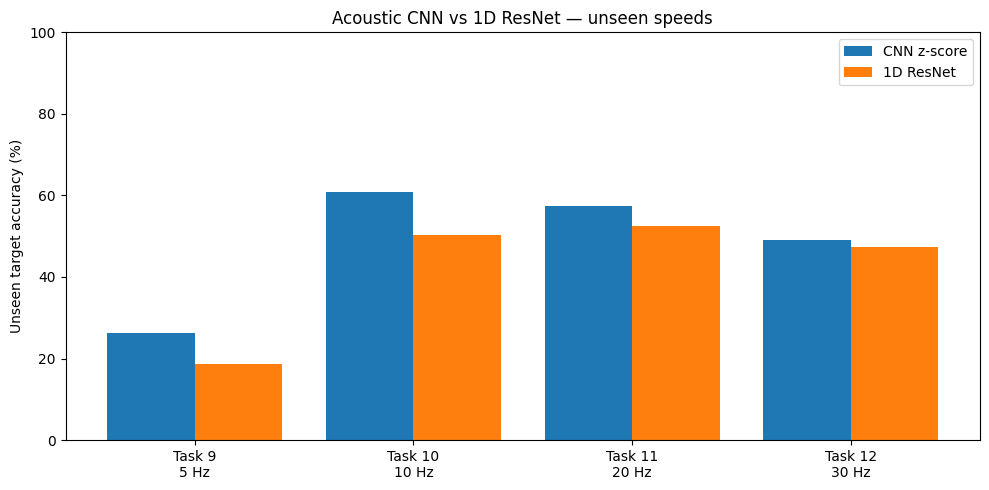

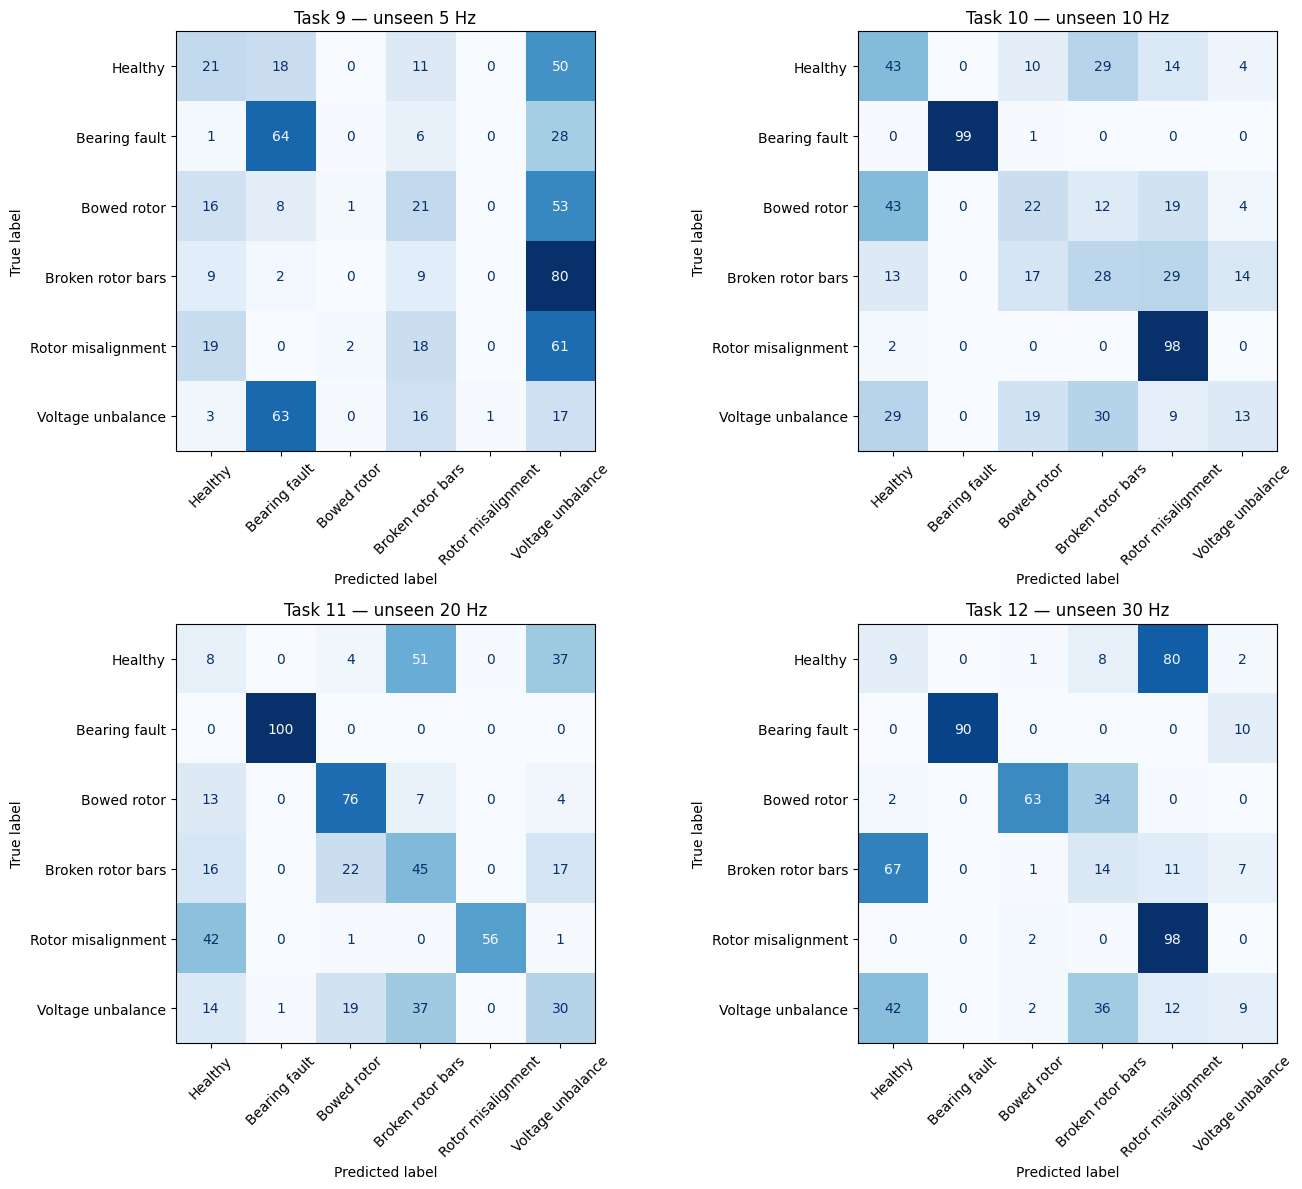

In [35]:
if READY_FOR_AGGREGATE:
    x = np.arange(4)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x-0.2, [CNN_ZSCORE[t] for t in TASKS], width=0.4, label='CNN z-score')
    ax.bar(x+0.2, [float(summary.loc[summary['task']==t, 'resnet_mean'].iloc[0])
                    for t in TASKS], width=0.4, label='1D ResNet')
    ax.set_xticks(x, [f'Task {t}\n{DOMAIN_HZ[TASK_TO_DOMAIN[t]]} Hz' for t in TASKS])
    ax.set_ylabel('Unseen target accuracy (%)')
    ax.set_title('Acoustic CNN vs 1D ResNet — unseen speeds')
    ax.set_ylim(0, 100)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR/'resnet_vs_cnn.png', dpi=180)
    plt.show()

    fig, axs = plt.subplots(2, 2, figsize=(14, 12))
    for ax, task in zip(axs.flat, TASKS):
        normalized = [cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
                      for cm in cms[task]]
        mean_cm = np.mean(normalized, axis=0) * 100
        ConfusionMatrixDisplay(mean_cm, display_labels=CLASS_NAMES).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='.0f',
            xticks_rotation=45)
        ax.set_title(f'Task {task} — unseen {DOMAIN_HZ[TASK_TO_DOMAIN[task]]} Hz')
    fig.tight_layout()
    fig.savefig(FIGURES_DIR/'resnet_confusion_matrices.png', dpi=160)
    plt.show()
else:
    print('Plots unavailable until all checkpoints are evaluated.')

## 17. Export per-sample predictions for team-level comparison (optional)

This output follows the team prediction-alignment format: `index, task, run, true, pred, speed_hz, class_code, block, win, start, rms_a, rms_v`. Each sample index refers to the **zero-based row of the verified v1.3 dataset**. Ten runs × 1,200 windows × four tasks = **48,000 rows**. Match across modalities using `index` (same dataset version) or `(class_code, speed_hz, start)`.

This export **does not retrain any models**. It requires 40 matching ResNet checkpoints and preserves target-test order.

In [36]:
EXPORT_PREDICTIONS = False  # Set True only after all 40 checkpoints exist.
if EXPORT_PREDICTIONS:
    assert READY_FOR_AGGREGATE, 'Need all 40 checkpoints.'
    prediction_rows = []
    with np.load(DATA_PATH) as d:
        class_codes = [str(c) for c in d['classes']]
        for task in TASKS:
            td = TASK_TO_DOMAIN[task]
            idx = np.flatnonzero((d['domain']==td) & (d['split']==1))
            parts = load_task(task)
            _, labels = parts['target']
            assert len(idx)==len(labels)==1200
            assert np.array_equal(d['y'][idx], labels)
            base = pd.DataFrame({'index':idx,'task':task,
                                 'speed_hz':DOMAIN_HZ[td],
                                 'class_code':[class_codes[c] for c in labels],
                                 'block':d['block'][idx], 'win':d['win'][idx],
                                 'start':d['start'][idx], 'rms_a':d['rms_a'][idx],
                                 'rms_v':d['rms_v'][idx]})
            loader = make_loader(parts['target'], shuffle=False)
            for seed in SEEDS:
                checkpoint = load_existing(checkpoint_path(task,seed),task,seed)
                model = AcousticResNet1D().to(DEVICE)
                model.load_state_dict(checkpoint['model_state_dict'])
                metrics = evaluate(model,loader)
                frame = base.copy()
                frame.insert(2, 'run', seed+1)
                frame.insert(3, 'true', metrics['y_true'])
                frame.insert(4, 'pred', metrics['y_pred'])
                prediction_rows.append(frame)
    prediction_df = pd.concat(prediction_rows,ignore_index=True)
    assert prediction_df.shape==(48000,12)
    assert not prediction_df.duplicated(['task','run','index']).any()
    output_path = RESULTS_DIR/'acoustic_predictions_resnet.csv'
    prediction_df.to_csv(output_path,index=False)
    print('Saved:',output_path)
else:
    print('Optional prediction export disabled.')

Optional prediction export disabled.


## 18. Save configuration and document limitations

**Interpretation guidance:**
- If ResNet improves target accuracy, the advantage might reflect skip connections, network capacity, downsampling, GAP, or their combination. This experiment **does not isolate** those factors.
- If ResNet does not improve, it is still a valid comparative result; inspect validation-target gaps and per-class failures.
- Dataset v1.3 and z-score preprocessing follow the previous acoustic setup. The prior z-score baseline used v1.0, so an exact array-level comparison should be verified before claiming normalization/version has zero effect.
- The reference paper's random split differs from this project's block-based split; paper numbers are contextual, not exactly controlled comparisons.
- The 5/10/20/30 Hz target recordings have already been inspected in earlier experiments, so this is an **exploratory research iteration**.

**Next experiment planned in the progress presentation:** 1D ResNet + supervised contrastive learning (SupCon), *after* the plain ResNet baseline is understood.

In [37]:
meta = {
    'university': 'Université de technologie de Compiègne (UTC)',
    'experiment': 'Acoustic 1D ResNet, no supervised contrastive learning',
    'architecture': ARCH_ID, 'dataset': DATA_PATH.name,
    'dataset_sha256': EXPECTED_SHA256,
    'preprocessing_repo': REPO_URL, 'preprocessing_commit': PREPROCESS_COMMIT,
    'normalization': NORM, 'optimizer': 'Adam', 'lr': BASE_LR,
    'lr_schedule': '0.0005 / (1 + 10*epoch/epochs)**0.75',
    'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'seeds': list(SEEDS),
    'selection': 'best source-validation accuracy',
    'target_test': 'unseen speed, split=1, eval_on=test, exploratory',
    'python': platform.python_version(), 'torch': torch.__version__,
    'cuda': torch.version.cuda, 'device': str(DEVICE),
    'recorded_at_utc': datetime.now(timezone.utc).isoformat()
}
metadata_path = RESULTS_DIR/'resnet_experiment_metadata.json'
with open(metadata_path, 'w') as file:
    json.dump(meta, file, indent=2, default=str)
print('Saved:', metadata_path)

Saved: /content/drive/MyDrive/HUSTmotor_Acoustic_ResNet/results/resnet_experiment_metadata.json
